<a href="https://colab.research.google.com/github/SlastuninAE/python-practice-algos/blob/master/636-01/hw-6-slastunin-a-e.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs, make_moons, make_circles, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, SpectralClustering
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
np.random.seed(42)

In [3]:
wine = load_wine()
X_wine = wine.data
y_true_wine = wine.target

X_wine_scaled = StandardScaler().fit_transform(X_wine)

pca = PCA(n_components=2, random_state=42)
X_wine_pca = pca.fit_transform(X_wine_scaled)

In [4]:
# KMeans
km_wine = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels_wine = km_wine.fit_predict(X_wine_scaled)

print(f"Silhouette Score: {silhouette_score(X_wine_scaled, km_labels_wine):.3f}")
print(f"Adjusted Rand Index (сравнение с истиной): {adjusted_rand_score(y_true_wine, km_labels_wine):.3f}")

Silhouette Score: 0.285
Adjusted Rand Index (сравнение с истиной): 0.897


In [13]:
# DBSCAN

for i in [0.001, 0.01, 0.1, 1, 1.5]:
  for j in [2, 3, 5, 8, 13, 21, 34, 55]:
    dbscan_wine = DBSCAN(eps=i, min_samples=j)
    labels_wine = dbscan_wine.fit_predict(X_wine_scaled)
    try:
      print(f"Silhouette Score для {i} и {j}: {silhouette_score(X_wine_scaled, labels_wine):.3f}")
    except:
      print(f"Ну тут всё ещё один кластер {i} и {j}")

Ну тут всё ещё один кластер 0.001 и 2
Ну тут всё ещё один кластер 0.001 и 3
Ну тут всё ещё один кластер 0.001 и 5
Ну тут всё ещё один кластер 0.001 и 8
Ну тут всё ещё один кластер 0.001 и 13
Ну тут всё ещё один кластер 0.001 и 21
Ну тут всё ещё один кластер 0.001 и 34
Ну тут всё ещё один кластер 0.001 и 55
Ну тут всё ещё один кластер 0.01 и 2
Ну тут всё ещё один кластер 0.01 и 3
Ну тут всё ещё один кластер 0.01 и 5
Ну тут всё ещё один кластер 0.01 и 8
Ну тут всё ещё один кластер 0.01 и 13
Ну тут всё ещё один кластер 0.01 и 21
Ну тут всё ещё один кластер 0.01 и 34
Ну тут всё ещё один кластер 0.01 и 55
Ну тут всё ещё один кластер 0.1 и 2
Ну тут всё ещё один кластер 0.1 и 3
Ну тут всё ещё один кластер 0.1 и 5
Ну тут всё ещё один кластер 0.1 и 8
Ну тут всё ещё один кластер 0.1 и 13
Ну тут всё ещё один кластер 0.1 и 21
Ну тут всё ещё один кластер 0.1 и 34
Ну тут всё ещё один кластер 0.1 и 55
Ну тут всё ещё один кластер 1 и 2
Ну тут всё ещё один кластер 1 и 3
Ну тут всё ещё один кластер 1 и 

In [14]:
dbscan_wine = DBSCAN(eps=1.5, min_samples=3)
labels_wine = dbscan_wine.fit_predict(X_wine_scaled)

In [15]:
print(f"Silhouette Score: {silhouette_score(X_wine_scaled, labels_wine):.3f}")
print(f"Adjusted Rand Index (сравнение с истиной): {adjusted_rand_score(y_true_wine, labels_wine):.3f}")

Silhouette Score: -0.277
Adjusted Rand Index (сравнение с истиной): 0.040


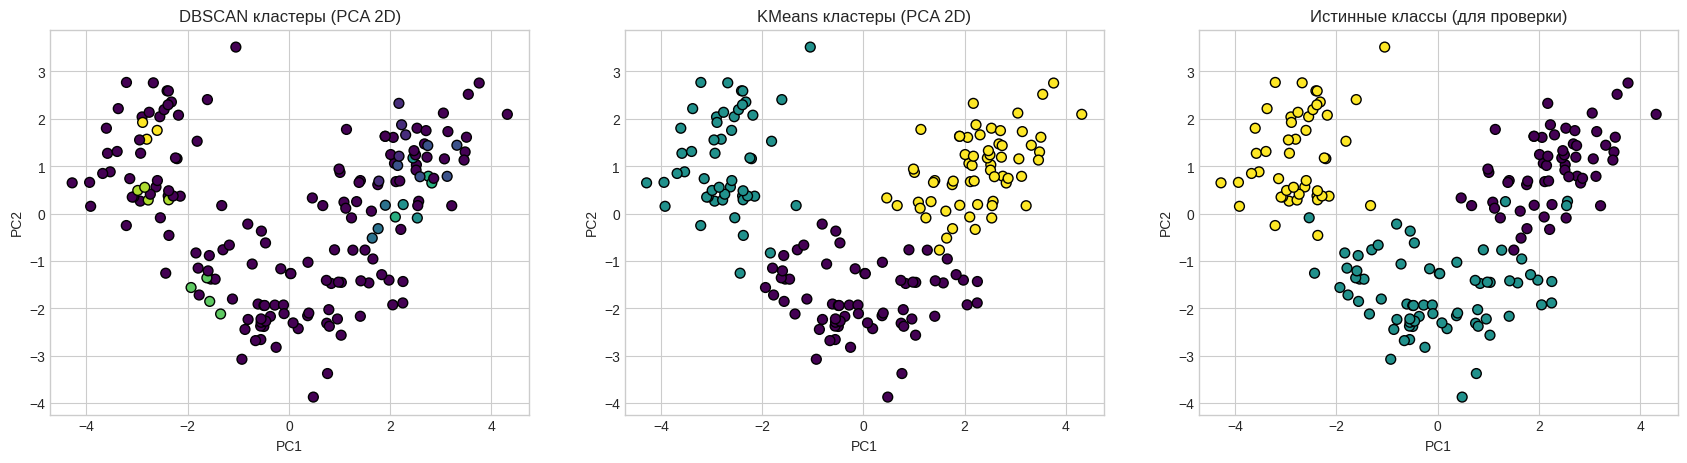

In [16]:
plt.figure(figsize=(21, 5))
plt.subplot(1, 3, 1)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=labels_wine, cmap='viridis', s=50, edgecolor='k')
plt.title('DBSCAN кластеры (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 3, 2)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=km_labels_wine, cmap='viridis', s=50, edgecolor='k')
plt.title('KMeans кластеры (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 3, 3)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=y_true_wine, cmap='viridis', s=50, edgecolor='k')
plt.title('Истинные классы (для проверки)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

Вывод:

KMeans лучше, он разбивает на три кластера почти как есть на самом деле, DBSCAN может разбить на кластеры только при eps=1.5 и  маленьких min_samples, но там Silhouette Score отрицательны, кластеры плохо разбиты